# Генерация синтетических данных и первичный EDA

Ноутбук формирует учебный датасет для рекомендательной системы режимов колонны К-2.

Принцип синтеза: `тип сырья + сезон + цель → профиль → параметры режима → результат → оценка пригодности`. Значения не генерируются полностью независимо: связанные технологические параметры рассчитываются через зависимости с шумом. Подробное обоснование приведено в `kr4/03-принцип-синтеза-данных.md`.

Этапы: справочники сырья и профилей, генерация режимов, упрощённая модель результатов, матрица пригодности и первичный анализ.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
N_MODES = 6000
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
DATA_DIR.mkdir(exist_ok=True)
plt.style.use('ggplot')
print(f'Каталог данных: {DATA_DIR.resolve()}')

Каталог данных: C:\Users\PC\curs\data


## 1. Справочники сырья и профилей

In [2]:
crude_types = pd.DataFrame({
    'crude_type': ['west_siberian_light', 'west_siberian_medium', 'heavy_mix', 'sour_mix', 'light_mix', 'arctic_mix', 'heavy_oil', 'condensate_mix'],
    'density_kg_m3': [825, 845, 900, 875, 815, 850, 920, 790],
    'sulfur_pct': [0.45, 0.75, 1.80, 2.10, 0.35, 1.05, 2.80, 0.20],
    'light_fraction_pct': [34, 29, 18, 22, 40, 27, 13, 48],
})
profiles = []
for crude in crude_types['crude_type']:
    for season in ['summer', 'winter']:
        for target in ['maximize_gasoline', 'maximize_diesel']:
            row = crude_types.loc[crude_types['crude_type'].eq(crude)].iloc[0]
            profiles.append({
                'profile_id': len(profiles), 'crude_type': crude, 'season': season, 'target_product': target,
                'feed_rate_tph': 220 if season == 'summer' else 205,
                'target_gasoline_pct': 25 + row['light_fraction_pct'] * 0.20 if target == 'maximize_gasoline' else 20,
                'target_diesel_pct': 35 if target == 'maximize_gasoline' else 38 + row['light_fraction_pct'] * 0.10,
                'max_sulfur_pct': 0.80 if target == 'maximize_gasoline' else 1.20, 'max_overlap_c': 10.0,
            })
profiles = pd.DataFrame(profiles)
print(f'Типов сырья: {len(crude_types)}; профилей: {len(profiles)}')
display(crude_types.head())
display(profiles.head())

Типов сырья: 8; профилей: 32


,crude_type,density_kg_m3,sulfur_pct,light_fraction_pct
0,west_siberian_light,825,0.45,34
1,west_siberian_medium,845,0.75,29
2,heavy_mix,900,1.80,18
3,sour_mix,875,2.10,22
4,light_mix,815,0.35,40


,profile_id,crude_type,season,target_product,feed_rate_tph,target_gasoline_pct,target_diesel_pct,max_sulfur_pct,max_overlap_c
0,0,west_siberian_light,summer,maximize_gasoline,220,31.8,35.0,0.8,10.0
1,1,west_siberian_light,summer,maximize_diesel,220,20.0,41.4,1.2,10.0
2,2,west_siberian_light,winter,maximize_gasoline,205,31.8,35.0,0.8,10.0
3,3,west_siberian_light,winter,maximize_diesel,205,20.0,41.4,1.2,10.0
4,4,west_siberian_medium,summer,maximize_gasoline,220,30.8,35.0,0.8,10.0


## 2. Генерация исторических режимов

In [3]:
mode_crude = rng.choice(crude_types['crude_type'], N_MODES)
mode_season = rng.choice(['summer', 'winter'], N_MODES)
crude_lookup = crude_types.set_index('crude_type')
density = pd.Series(mode_crude).map(crude_lookup['density_kg_m3']).to_numpy()
light_fraction = pd.Series(mode_crude).map(crude_lookup['light_fraction_pct']).to_numpy()
feed_rate = np.clip(rng.normal(215, 18, N_MODES), 170, 250)
feed_temp = np.clip(335 - 0.08 * (density - 825) + rng.normal(0, 7, N_MODES), 300, 360)
bottom_temp = np.clip(feed_temp + rng.normal(12, 4, N_MODES), 315, 370)
top_temp = np.clip(155 + 0.25 * (density - 825) + rng.normal(0, 5, N_MODES), 140, 190)
kerosene_temp = np.clip(205 + 0.12 * (density - 825) + rng.normal(0, 5, N_MODES), 180, 225)
light_diesel_temp = np.clip(250 + 0.12 * (density - 825) + rng.normal(0, 6, N_MODES), 220, 285)
heavy_diesel_temp = np.clip(315 + 0.10 * (density - 825) + rng.normal(0, 7, N_MODES), 280, 350)
top_pressure = np.clip(rng.normal(0.30, 0.055, N_MODES), 0.15, 0.50)
reflux = np.clip(rng.normal(72, 14, N_MODES), 35, 115)
pco_1 = np.clip(rng.normal(48, 10, N_MODES), 20, 80)
pco_2 = np.clip(rng.normal(42, 9, N_MODES), 18, 75)
steam_pct = np.clip(rng.normal(2.25, 0.42, N_MODES), 1.2, 3.5)
modes = pd.DataFrame({
    'mode_id': np.arange(N_MODES), 'crude_type': mode_crude, 'season': mode_season, 'feed_rate_tph': feed_rate.round(2),
    'feed_temp_c': feed_temp.round(2), 'top_temp_c': top_temp.round(2), 'bottom_temp_c': bottom_temp.round(2),
    'kerosene_temp_c': kerosene_temp.round(2), 'light_diesel_temp_c': light_diesel_temp.round(2), 'heavy_diesel_temp_c': heavy_diesel_temp.round(2),
    'top_pressure_mpa': top_pressure.round(4), 'reflux_tph': reflux.round(2), 'pco_1_tph': pco_1.round(2), 'pco_2_tph': pco_2.round(2), 'steam_pct': steam_pct.round(3),
})
modes['date'] = pd.date_range('2022-01-01', periods=N_MODES, freq='12h')
modes['shift'] = rng.choice(['day', 'night'], N_MODES)
display(modes.head())
print(modes.shape)

,mode_id,crude_type,season,feed_rate_tph,feed_temp_c,top_temp_c,bottom_temp_c,kerosene_temp_c,light_diesel_temp_c,heavy_diesel_temp_c,top_pressure_mpa,reflux_tph,pco_1_tph,pco_2_tph,steam_pct,date,shift
0,0,west_siberian_light,winter,196.33,336.12,149.92,350.14,204.76,254.12,321.38,0.3359,67.03,51.06,48.17,2.559,2022-01-01 00:00:00,day
1,1,heavy_oil,winter,223.69,333.65,175.92,353.09,221.78,265.89,322.64,0.3470,51.13,40.78,42.90,2.512,2022-01-01 12:00:00,day
2,2,arctic_mix,winter,204.06,337.24,164.06,343.91,208.20,253.70,313.37,0.2709,61.01,53.18,34.43,1.964,2022-01-02 00:00:00,day
3,3,sour_mix,winter,185.32,329.59,171.51,344.51,215.64,247.74,320.07,0.3658,83.18,48.09,55.40,1.621,2022-01-02 12:00:00,night
4,4,sour_mix,summer,209.83,338.23,169.11,354.09,209.49,253.81,319.69,0.2298,66.36,38.13,38.52,2.783,2022-01-03 00:00:00,day


(6000, 17)


## 3. Упрощённая модель «режим → результат»

In [4]:
reflux_norm = (reflux - 35) / 80
steam_norm = (steam_pct - 1.2) / 2.3
feed_norm = (feed_temp - 300) / 60
density_norm = np.clip((density - 790) / 130, 0, 1)
gasoline_yield = 16 + 0.42 * light_fraction + 4 * reflux_norm + 2 * feed_norm - 3 * density_norm
diesel_yield = 30 + 0.18 * light_fraction + 4 * steam_norm + 2 * (1 - reflux_norm) - 2 * feed_norm
kerosene_yield = 12 + 2 * reflux_norm + rng.normal(0, 1.2, N_MODES)
heavy_yield = 18 + 3 * density_norm + 2 * (1 - steam_norm) + rng.normal(0, 1.5, N_MODES)
residue_yield = 100 - gasoline_yield - diesel_yield - kerosene_yield - heavy_yield
overlap = np.clip(19 - 7 * reflux_norm - 4 * steam_norm + 5 * density_norm + rng.normal(0, 2.0, N_MODES), 3, 28)
sulfur = np.clip(pd.Series(mode_crude).map(crude_lookup['sulfur_pct']).to_numpy() * (1.0 - 0.10 * steam_norm) + rng.normal(0, 0.06, N_MODES), 0.05, None)
energy = np.clip(0.75 + 0.004 * feed_rate + 0.18 * steam_pct + 0.002 * reflux + rng.normal(0, 0.04, N_MODES), 1.0, None)
outcomes = pd.DataFrame({
    'mode_id': modes['mode_id'], 'gasoline_yield_pct': gasoline_yield, 'kerosene_yield_pct': kerosene_yield,
    'light_diesel_yield_pct': diesel_yield * 0.58, 'heavy_diesel_yield_pct': diesel_yield * 0.42, 'residue_yield_pct': residue_yield,
    'overlap_c': overlap, 'sulfur_pct': sulfur, 'energy_mwh_t': energy,
}).round(3)
modes = modes.merge(outcomes, on='mode_id')
display(modes.describe(include='all').T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
mode_id,6000.0,NaN,NaN,NaN,2999.5,0.0,1499.75,2999.5,4499.25,5999.0,1732.195139
crude_type,6000,8,west_siberian_medium,778,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,6000,2,summer,3013,NaN,NaN,NaN,NaN,NaN,NaN,NaN
feed_rate_tph,6000.0,NaN,NaN,NaN,214.620348,170.0,202.8075,214.29,226.975,250.0,17.643614
feed_temp_c,6000.0,NaN,NaN,NaN,332.910863,305.79,327.6075,332.865,338.09,360.0,7.749786
top_temp_c,6000.0,NaN,NaN,NaN,162.001833,140.0,153.49,161.315,170.4425,190.0,11.324511
bottom_temp_c,6000.0,NaN,NaN,NaN,345.054007,315.74,339.18,344.935,351.09,370.0,8.704544
kerosene_temp_c,6000.0,NaN,NaN,NaN,208.32452,186.71,203.34,208.15,213.26,225.0,6.972674
light_diesel_temp_c,6000.0,NaN,NaN,NaN,253.20382,225.08,247.6275,253.095,258.6725,278.63,7.875508
heavy_diesel_temp_c,6000.0,NaN,NaN,NaN,317.653415,286.43,312.12,317.61,323.2025,349.87,8.139967


## 4. Матрица пригодности «профиль × режим»

In [5]:
ratings = []
for profile in profiles.itertuples(index=False):
    same_crude = modes['crude_type'].eq(profile.crude_type)
    same_season = modes['season'].eq(profile.season)
    target_yield = modes['gasoline_yield_pct'] if profile.target_product == 'maximize_gasoline' else modes['light_diesel_yield_pct'] + modes['heavy_diesel_yield_pct']
    target_value = profile.target_gasoline_pct if profile.target_product == 'maximize_gasoline' else profile.target_diesel_pct
    quality_ok = (abs(target_yield - target_value) <= 5) & (modes['overlap_c'] <= profile.max_overlap_c) & (modes['sulfur_pct'] <= profile.max_sulfur_pct)
    close_conditions = same_crude & same_season
    score = np.where(quality_ok & close_conditions, 1.0, np.where(quality_ok, 0.5, np.where(close_conditions, -1.0, 0.0)))
    ratings.append(pd.DataFrame({'profile_id': profile.profile_id, 'mode_id': modes['mode_id'], 'rating': score.astype(float), 'relevant': quality_ok.astype(int)}))
ratings = pd.concat(ratings, ignore_index=True)
ratings.to_csv(DATA_DIR / 'profile_mode_ratings.csv', index=False)
modes.to_csv(DATA_DIR / 'modes.csv', index=False)
profiles.to_csv(DATA_DIR / 'profiles.csv', index=False)
crude_types.to_csv(DATA_DIR / 'crude_types.csv', index=False)
print(f'Матрица взаимодействий: {ratings.shape}')
print(f'Доля релевантных пар: {ratings.relevant.mean():.2%}')
display(ratings.head())

Матрица взаимодействий: (192000, 4)
Доля релевантных пар: 0.86%


,profile_id,mode_id,rating,relevant
0,0,0,0.0,0
1,0,1,0.0,0
2,0,2,0.0,0
3,0,3,0.0,0
4,0,4,0.0,0


## 5. Первичный EDA

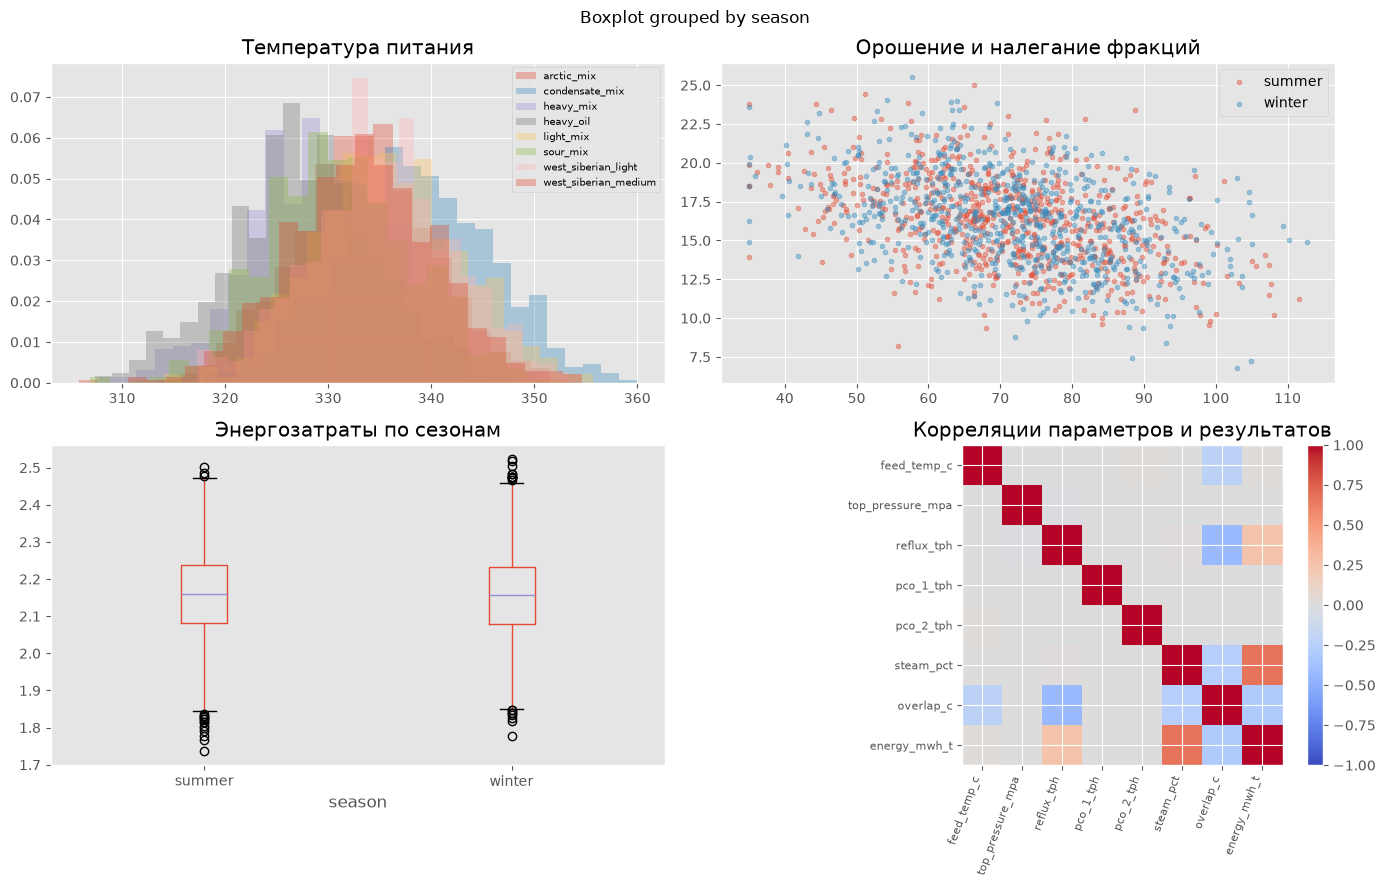

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for crude, group in modes.groupby('crude_type'):
    axes[0, 0].hist(group['feed_temp_c'], bins=24, alpha=0.35, density=True, label=crude)
axes[0, 0].legend(fontsize=7)
axes[0, 0].set_title('Температура питания')
for season, group in modes.groupby('season'):
    sample = group.sample(min(750, len(group)), random_state=SEED)
    axes[0, 1].scatter(sample['reflux_tph'], sample['overlap_c'], alpha=0.45, s=12, label=season)
axes[0, 1].legend()
axes[0, 1].set_title('Орошение и налегание фракций')
modes.boxplot(column='energy_mwh_t', by='season', ax=axes[1, 0], grid=False)
axes[1, 0].set_xlabel('season')
axes[1, 0].set_title('Энергозатраты по сезонам')
corr_cols = ['feed_temp_c', 'top_pressure_mpa', 'reflux_tph', 'pco_1_tph', 'pco_2_tph', 'steam_pct', 'overlap_c', 'energy_mwh_t']
corr = modes[corr_cols].corr()
image = axes[1, 1].imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
axes[1, 1].set_xticks(range(len(corr_cols)), corr_cols, rotation=70, ha='right', fontsize=8)
axes[1, 1].set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
fig.colorbar(image, ax=axes[1, 1], fraction=0.046, pad=0.04)
axes[1, 1].set_title('Корреляции параметров и результатов')
plt.tight_layout()
plt.show()

In [7]:
print('Пропуски:')
display(modes.isna().sum().sort_values(ascending=False).head())
print('Распределение оценок пригодности:')
display(ratings['rating'].value_counts(normalize=True).sort_index().rename('share'))
print('Средние показатели по типам сырья:')
display(modes.groupby('crude_type')[['gasoline_yield_pct', 'overlap_c', 'energy_mwh_t']].mean().round(2))

Пропуски:


mode_id          0
crude_type       0
season           0
feed_rate_tph    0
feed_temp_c      0
dtype: int64

Распределение оценок пригодности:


rating
-1.0    0.061812
 0.0    0.929594
 0.5    0.007906
 1.0    0.000687
Name: share, dtype: float64

Средние показатели по типам сырья:


,gasoline_yield_pct,overlap_c,energy_mwh_t
crude_type,,,
arctic_mix,28.89,16.18,2.16
condensate_mix,39.35,13.84,2.16
heavy_mix,23.83,18.13,2.16
heavy_oil,21.19,18.87,2.16
light_mix,35.24,14.87,2.15
sour_mix,26.15,17.16,2.15
west_siberian_light,32.50,15.33,2.16
west_siberian_medium,29.86,16.11,2.15


## Выводы по EDA

Сгенерировано 6000 режимов и 20 технологических профилей. Параметры находятся в заданных диапазонах, а шум создаёт перекрытие распределений. Выходы и качество зависят от сырья и управляющих параметров, поэтому датасет подходит для следующих этапов: kNN, ALS и гибридной модели.